In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

OpenCV version: 4.10.0


1 — Apply a basic blur to a selfie or group photo

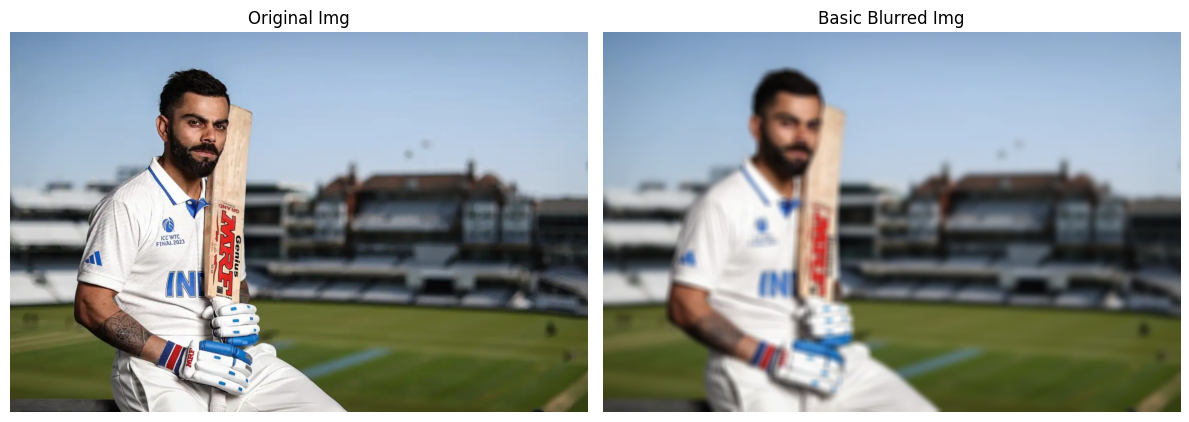

In [3]:
selfie_path = "cricketer_img.png"  
selfie = cv2.imread(selfie_path)

if selfie is None:
    print(f"Could not load {selfie_path}. Check the filename and folder.")
else:
    basic_blurred = cv2.blur(selfie, (15, 15))

    selfie_rgb = cv2.cvtColor(selfie, cv2.COLOR_BGR2RGB)
    blurred_rgb = cv2.cvtColor(basic_blurred, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(selfie_rgb)
    plt.title("Original Img")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(blurred_rgb)
    plt.title("Basic Blurred Img")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

2 — Reduce image noise using median blur

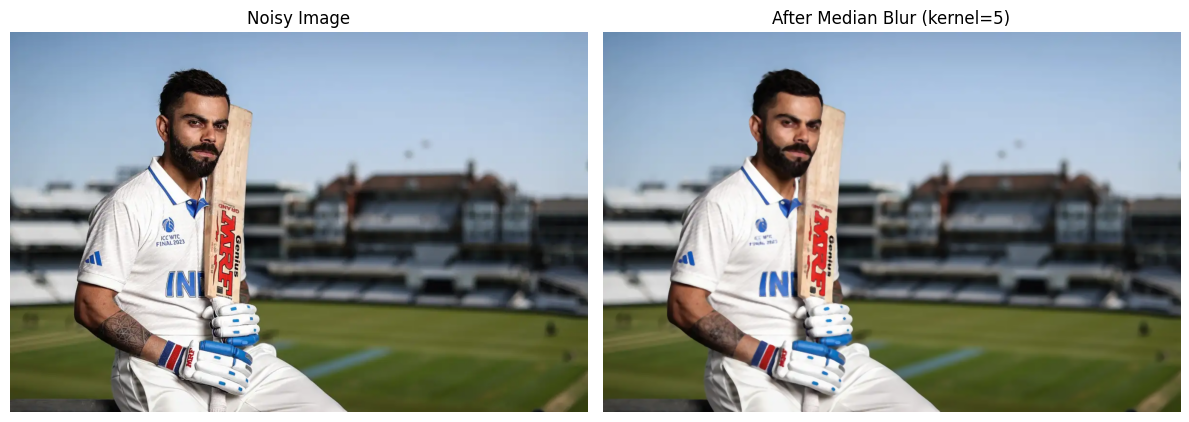

In [5]:
noisy_path = "cricketer_img.png"  
noisy = cv2.imread(noisy_path)

if noisy is None:
    print("No noisy_image.jpg found; creating a sample noisy image from the selfie.")
    if 'selfie' not in globals() or selfie is None:
        print("Please run Task 1 with a valid selfie.jpg first, or add noisy_image.jpg.")
        noisy = None
    else:
        rng = np.random.default_rng(42)
        noisy = selfie.copy()
        noise_mask = rng.random(noisy.shape[:2])
        noisy[noise_mask < 0.03] = (0, 0, 0)       # black pixels
        noisy[noise_mask > 0.97] = (255, 255, 255) # white pixels

if noisy is not None:
    median_filtered = cv2.medianBlur(noisy, 5) 

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB))
    plt.title("Noisy Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(median_filtered, cv2.COLOR_BGR2RGB))
    plt.title("After Median Blur (kernel=5)")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

3 — Apply Gaussian blur to an app screenshot

Saved as app_Img_blurred.jpg


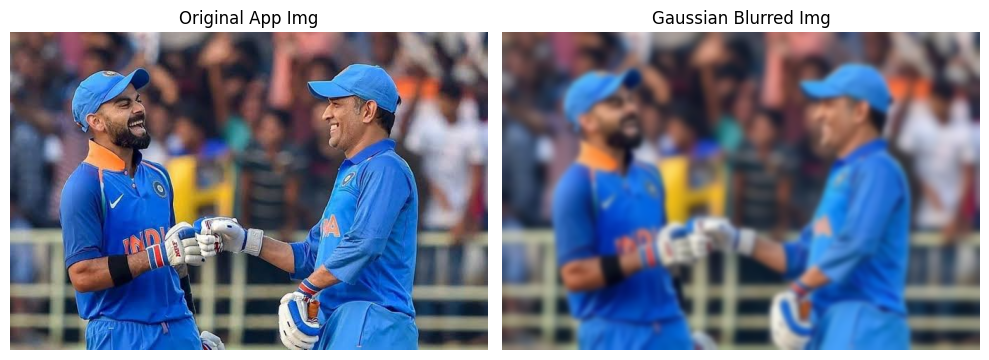

In [9]:
screenshot_path = "images.jpg"  
screenshot = cv2.imread(screenshot_path)

if screenshot is None:
    print(f"Could not load {screenshot_path}. Check the filename and folder.")
else:
    gaussian_blurred = cv2.GaussianBlur(screenshot, (21, 21), 0)
    cv2.imwrite("app_Img_blurred.jpg", gaussian_blurred)
    print("Saved as app_Img_blurred.jpg")

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(screenshot, cv2.COLOR_BGR2RGB))
    plt.title("Original App Img")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(gaussian_blurred, cv2.COLOR_BGR2RGB))
    plt.title("Gaussian Blurred Img")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

4 — Detect edges in a cricket match image or movie poster

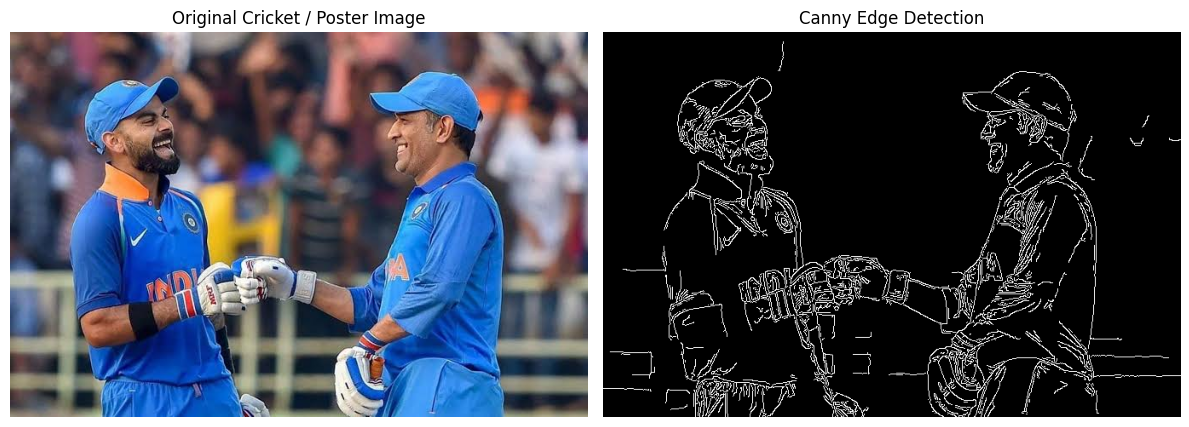

Observation: The most prominent edges usually appear around player outlines, bats, boundary lines, and other high-contrast details.


In [10]:
edge_path = "images.jpg" 
edge_image = cv2.imread(edge_path)

if edge_image is None:
    print(f"Could not load {edge_path}. Check the filename and folder.")
else:
    gray_for_edges = cv2.cvtColor(edge_image, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray_for_edges, 100, 200)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(edge_image, cv2.COLOR_BGR2RGB))
    plt.title("Original Cricket / Poster Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(edges, cmap="gray")
    plt.title("Canny Edge Detection")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    print("Observation: The most prominent edges usually appear around player outlines, bats, boundary lines, and other high-contrast details.")

5 — Apply Gaussian blur first, then Canny edge detection

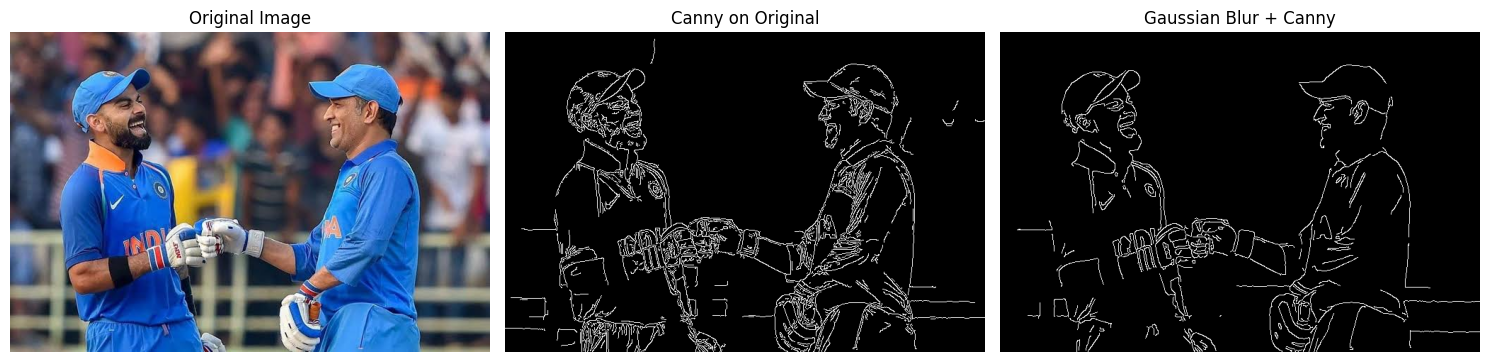

Observation: Gaussian blur reduces small noise and fine texture, so Canny often produces cleaner, less cluttered edges; too much blur can also remove thin details.


In [12]:
multi_path = "images.jpg"  
multi_image = cv2.imread(multi_path)

if multi_image is None:
    print(f"Could not load {multi_path}. Check the filename and folder.")
else:
    multi_gray = cv2.cvtColor(multi_image, cv2.COLOR_BGR2GRAY)

    # Canny directly on the original grayscale image
    edges_original = cv2.Canny(multi_gray, 100, 200)

    # Required sequence: Gaussian blur first, then Canny
    smoothed = cv2.GaussianBlur(multi_gray, (5, 5), 0)
    edges_after_blur = cv2.Canny(smoothed, 100, 200)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(multi_image, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(edges_original, cmap="gray")
    plt.title("Canny on Original")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(edges_after_blur, cmap="gray")
    plt.title("Gaussian Blur + Canny")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Observation: Gaussian blur reduces small noise and fine texture, so Canny often produces cleaner, less cluttered edges; too much blur can also remove thin details.")